# Лабораторная работа № 5. Исследование градиентного бустинга

**Цель работы** — исследовать градиентный бустинг для классификации манёвров робота и регрессии загрузки CPU, оценить качество на обучении и тесте и проследить его изменение по этапам.

Градиентный бустинг строит ансамбль последовательно. На каждом этапе новые деревья приближают отрицательный градиент функции потерь по текущим предсказаниям. Для квадратичной ошибки это разность между фактическим значением и текущим прогнозом. Прогноз новых деревьев добавляется к текущему с коэффициентом `learning_rate`. Для многоклассовой классификации на каждом этапе строится по одному дереву на класс. В случайном лесе деревья обучаются независимо на bootstrap-выборках, а их прогнозы усредняются.

## 1. Подготовка данных

Загрузим прежние CSV. Используем те же 24 признака робота и цель `class`, 21 признак CPU и цель `usr`. Сохраним последовательные срезы и зазор 90 строк перед тестовой выборкой робота.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

robot = pd.read_csv("data/wall_following_robot_24.csv")
cpu = pd.read_csv("data/cpu_act_44132.csv")

X_robot = robot.drop(columns="class")
y_robot = robot["class"]
X_cpu = cpu.drop(columns="usr")
y_cpu = cpu["usr"]

# Правая граница среза не включается.
robot_train = slice(0, 4274)
robot_test = slice(4364, 5456)
cpu_train = slice(0, 6553)
cpu_test = slice(6553, 8192)

assert len(robot) == robot_test.stop and len(cpu) == cpu_test.stop

X_robot_train, X_robot_test = X_robot.iloc[robot_train], X_robot.iloc[robot_test]
y_robot_train, y_robot_test = y_robot.iloc[robot_train], y_robot.iloc[robot_test]
X_cpu_train, X_cpu_test = X_cpu.iloc[cpu_train], X_cpu.iloc[cpu_test]
y_cpu_train, y_cpu_test = y_cpu.iloc[cpu_train], y_cpu.iloc[cpu_test]

print(f"Робот: {len(X_robot_train)} обучающих и {len(X_robot_test)} тестовых строк.")
print(f"CPU: {len(X_cpu_train)} обучающих и {len(X_cpu_test)} тестовых строк.")

Робот: 4274 обучающих и 1092 тестовых строк.
CPU: 6553 обучающих и 1639 тестовых строк.


## 2. Создание исходного бейзлайна и оценка качества

Обучим классификатор и регрессор со стандартными параметрами и `random_state=42`. Посчитаем Accuracy и F1-macro для классификации, MAE, RMSE и R² для регрессии на обучении и тесте.

In [2]:
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

robot_baseline = GradientBoostingClassifier(random_state=42)
cpu_baseline = GradientBoostingRegressor(random_state=42)
robot_baseline.fit(X_robot_train, y_robot_train)
cpu_baseline.fit(X_cpu_train, y_cpu_train)

y_robot_train_pred = robot_baseline.predict(X_robot_train)
y_robot_pred = robot_baseline.predict(X_robot_test)
y_cpu_train_pred = cpu_baseline.predict(X_cpu_train)
y_cpu_pred = cpu_baseline.predict(X_cpu_test)

samples = pd.Index(["Обучение", "Тест"], name="Выборка")
baseline_classification = pd.DataFrame([
    {"Accuracy": accuracy_score(actual, predicted),
     "F1-macro": f1_score(actual, predicted, average="macro")}
    for actual, predicted in [
        (y_robot_train, y_robot_train_pred), (y_robot_test, y_robot_pred),
    ]
], index=samples)

baseline_regression = pd.DataFrame([
    {"MAE, п. п.": mean_absolute_error(actual, predicted),
     "RMSE, п. п.": mean_squared_error(actual, predicted) ** 0.5,
     "R²": r2_score(actual, predicted)}
    for actual, predicted in [
        (y_cpu_train, y_cpu_train_pred), (y_cpu_test, y_cpu_pred),
    ]
], index=samples)

display(baseline_classification.round(4))
display(baseline_regression.round(4))

,Accuracy,F1-macro
Выборка,,
Обучение,1.0000,1.0000
Тест,0.9945,0.9955


,"MAE, п. п.","RMSE, п. п.",R²
Выборка,,,
Обучение,1.5704,2.1030,0.9874
Тест,1.8711,2.6379,0.9763


### Графики качества на тесте

Построим матрицу ошибок по манёврам робота. Для регрессии сопоставим фактические и предсказанные значения `usr`. Диагональ соответствует точному прогнозу.

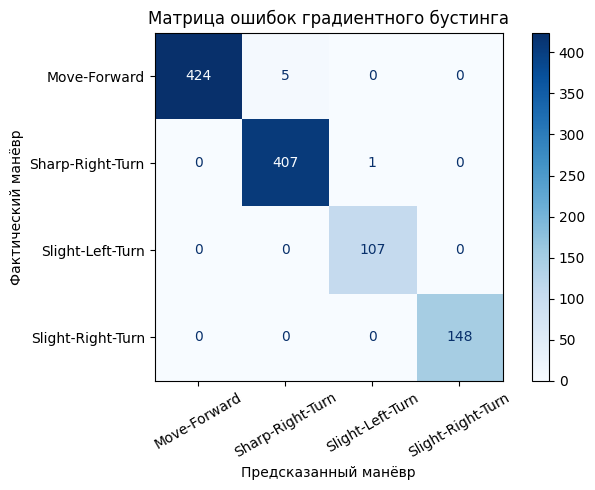

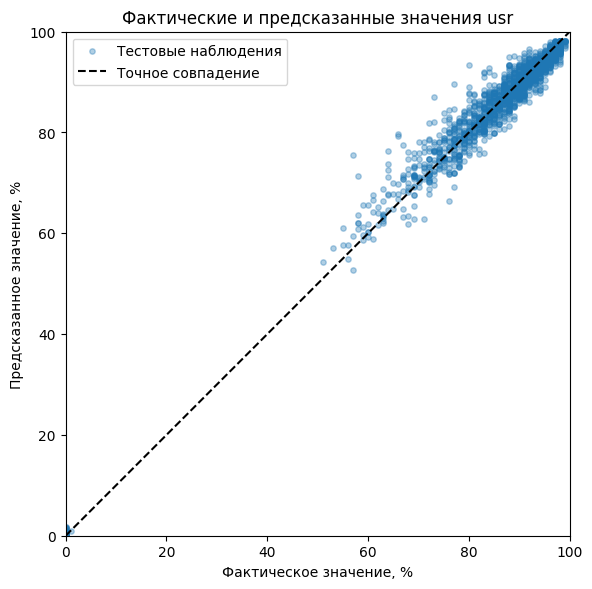

In [3]:
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay.from_predictions(
    y_robot_test, y_robot_pred, labels=robot_baseline.classes_,
    cmap="Blues", values_format="d", xticks_rotation=30, ax=ax,
)
ax.set(title="Матрица ошибок градиентного бустинга",
       xlabel="Предсказанный манёвр", ylabel="Фактический манёвр")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_cpu_test, y_cpu_pred, s=15, alpha=0.35, label="Тестовые наблюдения")
ax.plot([0, 100], [0, 100], "--", color="black", label="Точное совпадение")
ax.set(title="Фактические и предсказанные значения usr",
       xlabel="Фактическое значение, %", ylabel="Предсказанное значение, %",
       xlim=(0, 100), ylim=(0, 100), aspect="equal")
ax.legend()
fig.tight_layout()
plt.show()

### Качество по этапам бустинга

Через `staged_predict` получим прогнозы после каждого этапа и построим кривые F1-macro и MAE для обеих выборок. По горизонтали отложим номер этапа. В регрессии это также число деревьев, а в классификации на каждом этапе добавляется по дереву на класс. Тестовая кривая служит для описания уже обученной модели. Число этапов остаётся стандартным.

Робот, обучение: F1-macro 0.4478 → 1.0000
Робот, тест: F1-macro 0.4393 → 0.9955
CPU, обучение: MAE 9.8842 → 1.5704 п. п.
CPU, тест: MAE 9.4868 → 1.8711 п. п.


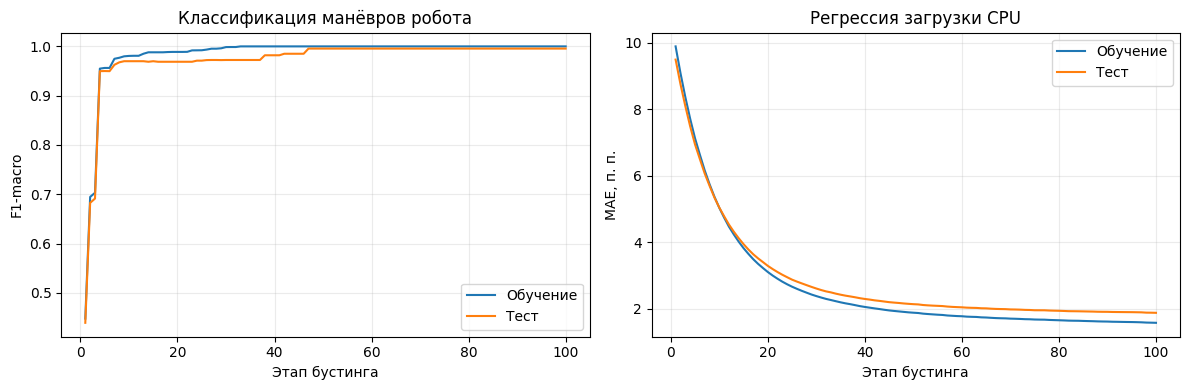

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for label, X, y in [
    ("Обучение", X_robot_train, y_robot_train), ("Тест", X_robot_test, y_robot_test),
]:
    scores = [
        f1_score(y, predicted, average="macro")
        for predicted in robot_baseline.staged_predict(X)
    ]
    axes[0].plot(range(1, len(scores) + 1), scores, label=label)
    print(f"Робот, {label.lower()}: F1-macro {scores[0]:.4f} → {scores[-1]:.4f}")

for label, X, y in [
    ("Обучение", X_cpu_train, y_cpu_train), ("Тест", X_cpu_test, y_cpu_test),
]:
    scores = [
        mean_absolute_error(y, predicted)
        for predicted in cpu_baseline.staged_predict(X)
    ]
    axes[1].plot(range(1, len(scores) + 1), scores, label=label)
    print(f"CPU, {label.lower()}: MAE {scores[0]:.4f} → {scores[-1]:.4f} п. п.")

axes[0].set(title="Классификация манёвров робота", xlabel="Этап бустинга", ylabel="F1-macro")
axes[1].set(title="Регрессия загрузки CPU", xlabel="Этап бустинга", ylabel="MAE, п. п.")
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

### Выводы

- **Классификация.** На обучении Accuracy и F1-macro равны 1,0000. На тесте Accuracy составила 0,9945, F1-macro — 0,9955. Между первым и сотым этапами тестовый F1-macro вырос с 0,4393 до 0,9955.
- **Регрессия.** MAE составила 1,5704 п. п. на обучении и 1,8711 п. п. на тесте. На тесте RMSE равна 2,6379 п. п., R² — 0,9763. Между первым и сотым этапами тестовая MAE снизилась с 9,4868 до 1,8711 п. п.
- На тех же тестовых выборках бустинг показал более высокий F1-macro, чем исходный случайный лес из лабораторной № 4 (0,9955 против 0,9863). Для регрессии у бустинга чуть выше MAE (1,8711 против 1,8437 п. п.), но чуть ниже RMSE (2,6379 против 2,6762 п. п.).

## 3. Улучшение бейзлайна

1. Увеличение `n_estimators` со 100 до 150 может улучшить качество за счёт дополнительных этапов коррекции. При 50 этапах модель может недообучиться.
2. При фиксированных 100 этапах `learning_rate=0.05` может замедлить обучение, а `0.2` — ускорить его. При слишком крупных шагах качество на валидации может ухудшиться.
3. Деревья глубины 2 могут хуже учитывать взаимодействия признаков. Глубина 5 позволяет описывать более сложные зависимости, но повышает риск переобучения.

Зададим сетку параметров и три последовательных разбиения обучающих выборок. Для робота оставим зазор 90 строк перед каждым валидационным блоком.

In [5]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit, cross_val_score

boosting_grid = {
    "n_estimators": [50, 100, 150],
    "learning_rate": [0.05, 0.1, 0.2],
    "max_depth": [2, 3, 5],
}
robot_cv = TimeSeriesSplit(n_splits=3, gap=90)
cpu_cv = TimeSeriesSplit(n_splits=3)


### Случайный поиск

Для каждой задачи проверим восемь комбинаций. Выберем максимальный средний F1-macro для робота и минимальную среднюю MAE для CPU. Поиск выполняется последовательно и переобучает победителя на всей обучающей выборке.

In [6]:
def search_boosting(model, X, y, cv, scoring):
    search = RandomizedSearchCV(
        model, boosting_grid, n_iter=8, scoring=scoring, cv=cv,
        random_state=42, n_jobs=1, verbose=2, error_score="raise",
    )
    search.fit(X, y)
    return search


print("Подбор для робота", flush=True)
robot_search = search_boosting(
    GradientBoostingClassifier(random_state=42),
    X_robot_train, y_robot_train, robot_cv, "f1_macro",
)
best_robot_boosting_params = robot_search.best_params_
robot_improved = robot_search.best_estimator_
print(f"Параметры робота {best_robot_boosting_params}")
print(f"Средний F1-macro на CV = {robot_search.best_score_:.4f}")

print("Подбор для CPU", flush=True)
cpu_search = search_boosting(
    GradientBoostingRegressor(random_state=42),
    X_cpu_train, y_cpu_train, cpu_cv, "neg_mean_absolute_error",
)
best_cpu_boosting_params = cpu_search.best_params_
cpu_improved = cpu_search.best_estimator_
print(f"Параметры CPU {best_cpu_boosting_params}")
print(f"Средняя MAE на CV = {-cpu_search.best_score_:.4f} п. п.")


Подбор для робота
Fitting 3 folds for each of 8 candidates, totalling 24 fits
[CV] END ..learning_rate=0.05, max_depth=5, n_estimators=150; total time=  12.0s
[CV] END ..learning_rate=0.05, max_depth=5, n_estimators=150; total time=  23.6s
[CV] END ..learning_rate=0.05, max_depth=5, n_estimators=150; total time=  35.0s
[CV] END ...learning_rate=0.1, max_depth=3, n_estimators=100; total time=   4.8s
[CV] END ...learning_rate=0.1, max_depth=3, n_estimators=100; total time=   9.4s
[CV] END ...learning_rate=0.1, max_depth=3, n_estimators=100; total time=  14.0s
[CV] END ....learning_rate=0.1, max_depth=2, n_estimators=50; total time=   1.7s
[CV] END ....learning_rate=0.1, max_depth=2, n_estimators=50; total time=   3.2s
[CV] END ....learning_rate=0.1, max_depth=2, n_estimators=50; total time=   4.7s
[CV] END ....learning_rate=0.2, max_depth=3, n_estimators=50; total time=   2.3s
[CV] END ....learning_rate=0.2, max_depth=3, n_estimators=50; total time=   4.7s
[CV] END ....learning_rate=0.2,

### Проверка гипотез

На тех же фолдах оценим стандартную конфигурацию и шесть вариантов, в каждом из которых меняется один параметр. В таблицах покажем оценки по фолдам и их среднее. MAE вернём к обычному положительному знаку.

In [7]:
standard_params = {"n_estimators": 100, "learning_rate": 0.1, "max_depth": 3}
variants = [("Стандартная", standard_params)]
for parameter, values in boosting_grid.items():
    for value in values:
        if value != standard_params[parameter]:
            variants.append((f"{parameter}={value}", {**standard_params, parameter: value}))


def compare_variants(model_class, X, y, cv, scoring, metric, sign):
    rows = []
    for label, params in variants:
        print(label, flush=True)
        scores = sign * cross_val_score(
            model_class(random_state=42, **params), X, y, cv=cv,
            scoring=scoring, n_jobs=1, error_score="raise",
        )
        rows.append({
            "Конфигурация": label, **params,
            "Фолд 1": scores[0], "Фолд 2": scores[1], "Фолд 3": scores[2],
            metric: scores.mean(),
        })
    return pd.DataFrame(rows).set_index("Конфигурация")


print("Робот · F1-macro")
robot_hypotheses = compare_variants(
    GradientBoostingClassifier, X_robot_train, y_robot_train,
    robot_cv, "f1_macro", "Средний F1-macro", 1,
)
display(robot_hypotheses.round(4))

print("CPU · MAE, п. п.")
cpu_hypotheses = compare_variants(
    GradientBoostingRegressor, X_cpu_train, y_cpu_train,
    cpu_cv, "neg_mean_absolute_error", "Средняя MAE, п. п.", -1,
)
display(cpu_hypotheses.round(4))


Робот · F1-macro
Стандартная
n_estimators=50
n_estimators=150
learning_rate=0.05
learning_rate=0.2
max_depth=2
max_depth=5


,n_estimators,learning_rate,max_depth,Фолд 1,Фолд 2,Фолд 3,Средний F1-macro
Конфигурация,,,,,,,
Стандартная,100,0.10,3,0.9098,0.9668,0.9889,0.9552
n_estimators=50,50,0.10,3,0.9069,0.9554,0.9889,0.9504
n_estimators=150,150,0.10,3,0.9098,0.9723,0.9889,0.9570
learning_rate=0.05,100,0.05,3,0.9098,0.9565,0.9889,0.9517
learning_rate=0.2,100,0.20,3,0.9098,0.9728,0.9889,0.9572
max_depth=2,100,0.10,2,0.9057,0.9653,0.9889,0.9533
max_depth=5,100,0.10,5,0.9033,0.9026,0.9927,0.9329


CPU · MAE, п. п.
Стандартная
n_estimators=50
n_estimators=150
learning_rate=0.05
learning_rate=0.2
max_depth=2
max_depth=5


,n_estimators,learning_rate,max_depth,Фолд 1,Фолд 2,Фолд 3,"Средняя MAE, п. п."
Конфигурация,,,,,,,
Стандартная,100,0.10,3,1.8194,1.7538,1.7370,1.7701
n_estimators=50,50,0.10,3,2.0266,1.9753,1.9829,1.9949
n_estimators=150,150,0.10,3,1.7742,1.6967,1.6731,1.7147
learning_rate=0.05,100,0.05,3,2.0269,1.9658,1.9707,1.9878
learning_rate=0.2,100,0.20,3,1.7960,1.7010,1.6649,1.7207
max_depth=2,100,0.10,2,1.9862,1.9442,1.9377,1.9560
max_depth=5,100,0.10,5,1.7187,1.6384,1.5991,1.6521


### Сравнение на тестовых выборках

Оценим выбранные модели на прежних тестовых выборках. Сравним с исходным бейзлайном по Accuracy и F1-macro для робота и по MAE, RMSE и R² для CPU.

In [8]:
y_robot_improved = robot_improved.predict(X_robot_test)
y_cpu_improved = cpu_improved.predict(X_cpu_test)

robot_test_results = pd.DataFrame([
    baseline_classification.loc["Тест"].to_dict(),
    {"Accuracy": accuracy_score(y_robot_test, y_robot_improved),
     "F1-macro": f1_score(y_robot_test, y_robot_improved, average="macro")},
], index=["Бейзлайн", "После подбора"])
cpu_test_results = pd.DataFrame([
    baseline_regression.loc["Тест"].to_dict(),
    {"MAE, п. п.": mean_absolute_error(y_cpu_test, y_cpu_improved),
     "RMSE, п. п.": mean_squared_error(y_cpu_test, y_cpu_improved) ** 0.5,
     "R²": r2_score(y_cpu_test, y_cpu_improved)},
], index=["Бейзлайн", "После подбора"])

display(robot_test_results.round(4))
display(cpu_test_results.round(4))


,Accuracy,F1-macro
Бейзлайн,0.9945,0.9955
После подбора,0.9945,0.9955


,"MAE, п. п.","RMSE, п. п.",R²
Бейзлайн,1.8711,2.6379,0.9763
После подбора,1.7072,2.4542,0.9795


На первых двух графиках покажем отклонение средних CV-метрик от стандартной конфигурации. Затем сравним все пять тестовых метрик на отдельных шкалах.

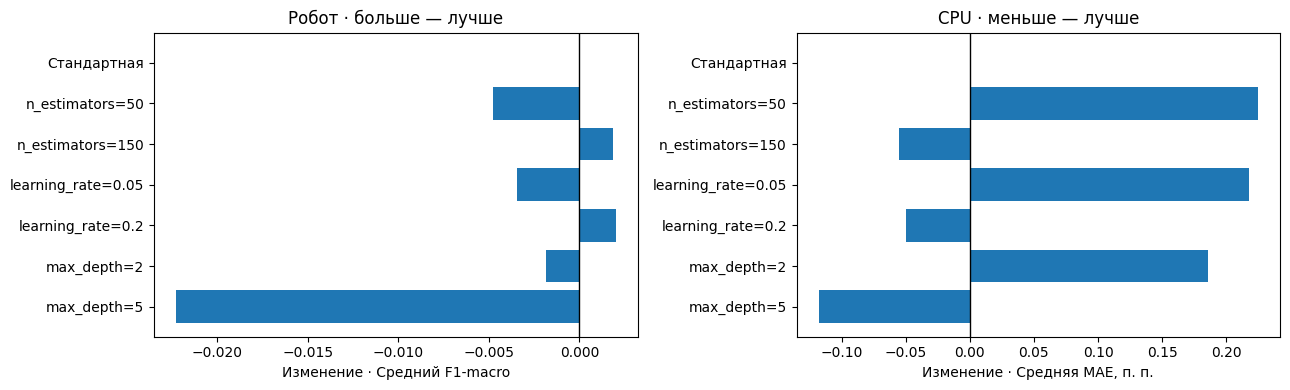

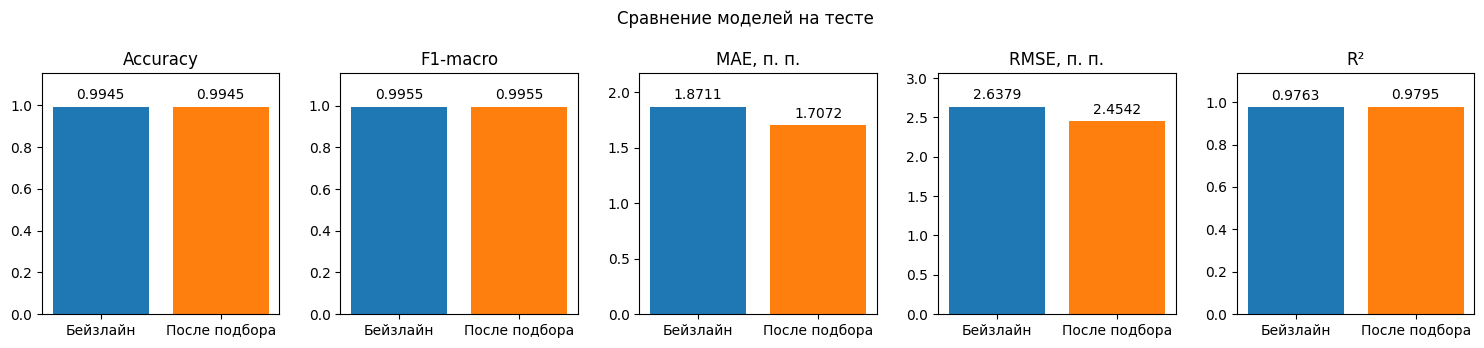

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, table, metric, title in [
    (axes[0], robot_hypotheses, "Средний F1-macro", "Робот · больше — лучше"),
    (axes[1], cpu_hypotheses, "Средняя MAE, п. п.", "CPU · меньше — лучше"),
]:
    delta = table[metric] - table.loc["Стандартная", metric]
    ax.barh(delta.index, delta)
    ax.axvline(0, color="black", linewidth=1)
    ax.invert_yaxis()
    ax.set(title=title, xlabel=f"Изменение · {metric}")
fig.tight_layout()
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 5, figsize=(15, 3.5))
test_metrics = list(robot_test_results.items()) + list(cpu_test_results.items())
for ax, (metric, scores) in zip(axes, test_metrics):
    bars = ax.bar(scores.index, scores.values, color=["tab:blue", "tab:orange"])
    ax.bar_label(bars, fmt="%.4f", padding=3)
    ax.set_title(metric)
    ax.set_ylim(0, scores.max() * 1.16)
fig.suptitle("Сравнение моделей на тесте")
fig.tight_layout()
plt.show()
plt.close(fig)


### Выводы

- **Число этапов.** При переходе со 100 до 50 этапов качество на кросс-валидации снизилось в обеих задачах. При 150 этапах средний F1-macro вырос с 0,9552 до 0,9570, а MAE снизилась с 1,7701 до 1,7147 п. п.
- **Скорость обучения.** При 100 этапах шаг 0,05 ухудшил обе метрики. Шаг 0,2 улучшил их относительно 0,1. Средний F1-macro достиг 0,9572, а MAE снизилась до 1,7207 п. п.
- **Глубина деревьев.** При глубине 2 и остальных стандартных параметрах обе метрики ухудшились. При глубине 5 средний F1-macro снизился до 0,9329, а MAE улучшилась до 1,6521 п. п. В сочетании со 150 этапами глубина 2 дала лучший результат случайного поиска для робота.
- **Робот.** Подбор повысил средний F1-macro на кросс-валидации с 0,9552 до 0,9574. На тесте Accuracy и F1-macro совпали с бейзлайном до четырёх знаков (0,9945 и 0,9955).
- **CPU.** Подбор снизил среднюю MAE на кросс-валидации с 1,7701 до 1,6311 п. п. На тесте MAE снизилась с 1,8711 до 1,7072 п. п., RMSE — с 2,6379 до 2,4542 п. п., а R² вырос с 0,9763 до 0,9795.


## 4. Самостоятельная реализация алгоритма

На каждом этапе градиентный бустинг добавляет к текущему прогнозу дерево, умноженное на скорость обучения. Дерево приближает отрицательный градиент функции потерь по текущим прогнозам. Для половины квадратичной ошибки это остаток $y-F$. Для многоклассовой кросс-энтропии отрицательный градиент по логиту класса $k$ равен $r_k=y_k-p_k$, где $y_k$ — индикатор класса, а $p_k$ — вероятность после Softmax.

Возьмём регрессионное дерево из лабораторной № 3 за основу. Сохраним перебор порогов между различными соседними значениями и расчёт сумм квадратов ошибок через накопленные суммы. Отсортируем индексы по каждому признаку один раз на обучающую выборку и будем передавать отсортированные подмножества в дочерние узлы. В классификации значение листа скорректируем по формуле Ньютона

$$\gamma_k=\frac{K-1}{K}\frac{\sum_{i\in R}(y_{ik}-p_{ik})}{\sum_{i\in R}p_{ik}(1-p_{ik})},$$

где $K$ — число классов, $R$ — обучающие объекты в листе. При почти нулевом знаменателе положим поправку равной нулю.

In [10]:
import numpy as np


class BoostingRegressionTree:
    def __init__(self, max_depth, rng):
        self.max_depth = max_depth
        self.rng = rng

    def fit(self, X, y, orders, curvature=None, correction=1.0):
        self.tree_ = self._grow(X, y, orders, 0, curvature, correction)
        return self

    def _best_split(self, X, y, orders, indices):
        n = len(indices)
        mean = y[indices].mean()
        best_cost = np.inf
        best_split = None
        for feature in self.rng.permutation(X.shape[1]):
            order = orders[feature]
            values = X[order, feature]
            cuts = np.flatnonzero(values[:-1] < values[1:]) + 1
            if cuts.size == 0:
                continue

            targets = y[order] - mean
            prefix = np.cumsum(targets)
            squared_prefix = np.cumsum(targets ** 2)
            left = prefix[cuts - 1]
            right = prefix[-1] - left
            left_sse = squared_prefix[cuts - 1] - left ** 2 / cuts
            right_sse = squared_prefix[-1] - squared_prefix[cuts - 1] - right ** 2 / (n - cuts)
            costs = np.maximum(left_sse, 0) + np.maximum(right_sse, 0)

            i = np.argmin(costs)
            if costs[i] < best_cost:
                best_cost = costs[i]
                cut = cuts[i]
                lower, upper = values[cut - 1], values[cut]
                threshold = lower / 2 + upper / 2
                if not lower <= threshold < upper:
                    threshold = lower
                best_split = feature, threshold, cut
        return best_split

    def _grow(self, X, y, orders, depth, curvature, correction):
        indices = orders[0]
        stop = depth >= self.max_depth or len(indices) < 2 or np.all(y[indices] == y[indices[0]])
        split = None if stop else self._best_split(X, y, orders, indices)
        if split is None:
            if curvature is None:
                return y[indices].mean()
            denominator = curvature[indices].sum()
            if denominator <= 1e-15:
                return 0.0
            return correction * y[indices].sum() / denominator

        feature, threshold, cut = split
        left = X[orders, feature] <= threshold
        left_orders = orders[left].reshape(X.shape[1], cut)
        right_orders = orders[~left].reshape(X.shape[1], len(indices) - cut)
        return (
            feature, threshold,
            self._grow(X, y, left_orders, depth + 1, curvature, correction),
            self._grow(X, y, right_orders, depth + 1, curvature, correction),
        )

    def predict(self, X):
        predictions = np.empty(len(X))

        def fill(node, indices):
            if not indices.size:
                return
            if not isinstance(node, tuple):
                predictions[indices] = node
                return
            feature, threshold, left, right = node
            goes_left = X[indices, feature] <= threshold
            fill(left, indices[goes_left])
            fill(right, indices[~goes_left])

        fill(self.tree_, np.arange(len(X)))
        return predictions


Начнём регрессию со среднего значения цели. На каждом этапе обучим дерево на остатках и добавим его прогноз с коэффициентом `learning_rate`. Сохраним среднюю квадратичную ошибку до первого дерева и после каждого этапа.

In [11]:
def boosting_features(X, n_features=None):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2 or not X.shape[1] or not np.isfinite(X).all():
        raise ValueError("Ожидается матрица конечных чисел.")
    if n_features is not None and X.shape[1] != n_features:
        raise ValueError("Число признаков отличается от обучающей выборки.")
    return X


class _GradientBoosting:
    def __init__(self, n_estimators=100, learning_rate=0.1, max_depth=3, random_state=None):
        self.n_estimators = n_estimators
        self.learning_rate = learning_rate
        self.max_depth = max_depth
        self.random_state = random_state

    def _prepare_fit(self, X, y):
        X = boosting_features(X)
        if not len(X) or y.shape != (len(X),):
            raise ValueError("Нужны непустая выборка и одномерная цель.")
        if not isinstance(self.n_estimators, (int, np.integer)) or self.n_estimators < 1:
            raise ValueError("n_estimators должен быть положительным целым числом.")
        if not isinstance(self.max_depth, (int, np.integer)) or self.max_depth < 1:
            raise ValueError("max_depth должен быть положительным целым числом.")
        if not np.isfinite(self.learning_rate) or self.learning_rate <= 0:
            raise ValueError("learning_rate должен быть конечным положительным числом.")
        self.n_features_in_ = X.shape[1]
        self.trees_ = []
        return X, np.argsort(X, axis=0, kind="stable").T.copy(), np.random.default_rng(self.random_state)

    def _prepare_predict(self, X):
        if not hasattr(self, "trees_"):
            raise ValueError("Сначала вызовите fit.")
        return boosting_features(X, self.n_features_in_)

    def _progress(self, stage):
        if stage % 10 == 0:
            print(f"Этап {stage}/{self.n_estimators}, потери {self.loss_history_[-1]:.6f}", flush=True)


class GradientBoostingRegressor(_GradientBoosting):
    def fit(self, X, y):
        y = np.asarray(y, dtype=float)
        if not np.isfinite(y).all():
            raise ValueError("Цель регрессии должна содержать конечные числа.")
        X, orders, rng = self._prepare_fit(X, y)
        self.initial_prediction_ = y.mean()
        predictions = np.full(len(y), self.initial_prediction_)
        self.loss_history_ = [np.mean((y - predictions) ** 2)]
        for stage in range(1, self.n_estimators + 1):
            tree = BoostingRegressionTree(self.max_depth, rng).fit(X, y - predictions, orders)
            self.trees_.append(tree)
            predictions += self.learning_rate * tree.predict(X)
            self.loss_history_.append(np.mean((y - predictions) ** 2))
            self._progress(stage)
        return self

    def predict(self, X):
        X = self._prepare_predict(X)
        predictions = np.full(len(X), self.initial_prediction_)
        for tree in self.trees_:
            predictions += self.learning_rate * tree.predict(X)
        return predictions


Для классификации начальные логиты равны логарифмам частот классов. Перед экспонентой вычтем из каждой строки её максимум. На одном этапе все деревья используют одни и те же вероятности, вычисленные перед этим этапом.

In [12]:
def softmax(logits):
    shifted = logits - logits.max(axis=1, keepdims=True)
    weights = np.exp(shifted)
    return weights / weights.sum(axis=1, keepdims=True)


def multiclass_loss(logits, targets):
    shifted = logits - logits.max(axis=1, keepdims=True)
    actual = shifted[np.arange(len(targets)), targets]
    return np.mean(np.log(np.exp(shifted).sum(axis=1)) - actual)


class GradientBoostingClassifier(_GradientBoosting):
    def fit(self, X, y):
        y = np.asarray(y)
        X, orders, rng = self._prepare_fit(X, y)
        self.classes_, targets, counts = np.unique(y, return_inverse=True, return_counts=True)
        n_classes = len(self.classes_)
        if n_classes < 2:
            raise ValueError("Для классификации нужны хотя бы два класса.")
        self.initial_logits_ = np.log(counts / len(y))
        logits = np.tile(self.initial_logits_, (len(y), 1))
        indicators = targets[:, None] == np.arange(n_classes)
        self.loss_history_ = [multiclass_loss(logits, targets)]

        for stage in range(1, self.n_estimators + 1):
            probabilities = softmax(logits)
            residuals = indicators - probabilities
            curvature = probabilities * (1 - probabilities)
            trees = []
            for k in range(n_classes):
                tree = BoostingRegressionTree(self.max_depth, rng).fit(
                    X, residuals[:, k], orders, curvature[:, k], (n_classes - 1) / n_classes,
                )
                trees.append(tree)
                logits[:, k] += self.learning_rate * tree.predict(X)
            self.trees_.append(trees)
            self.loss_history_.append(multiclass_loss(logits, targets))
            self._progress(stage)
        return self

    def predict_proba(self, X):
        X = self._prepare_predict(X)
        logits = np.tile(self.initial_logits_, (len(X), 1))
        for trees in self.trees_:
            for k, tree in enumerate(trees):
                logits[:, k] += self.learning_rate * tree.predict(X)
        return softmax(logits)

    def predict(self, X):
        return self.classes_[self.predict_proba(X).argmax(axis=1)]


OwnGradientBoostingRegressor = GradientBoostingRegressor
OwnGradientBoostingClassifier = GradientBoostingClassifier
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor


Проверим регрессию на ступенчатой зависимости, а классификацию — на трёх группах разного размера. Для каждой задачи дважды обучим модель с одинаковым `random_state` и сравним прогнозы и потери. График покажет изменение потерь с нулевого этапа.

Этап 10/20, потери 0.125540
Этап 20/20, потери 0.001447
Этап 10/20, потери 0.125540
Этап 20/20, потери 0.001447
Этап 10/20, потери 0.051231
Этап 20/20, потери 0.003498
Этап 10/20, потери 0.051231
Этап 20/20, потери 0.003498
Проверки прогнозов, воспроизводимости и снижения потерь пройдены.


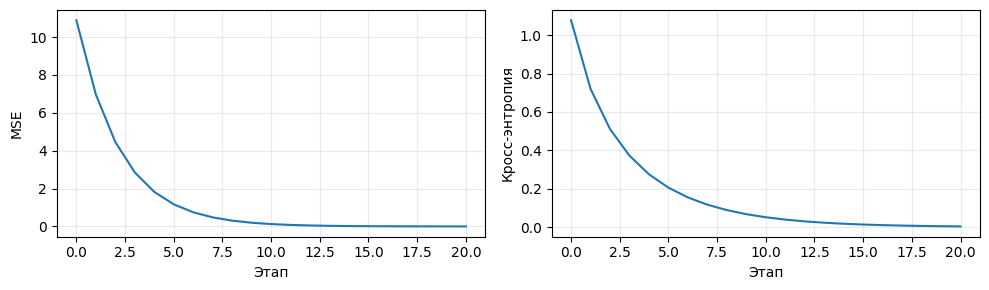

In [13]:
toy_X = np.arange(12, dtype=float).reshape(-1, 1)
toy_reg_y = np.repeat([1.0, 4.0, 9.0], [3, 4, 5])
toy_cls_y = np.repeat(["A", "B", "C"], [3, 4, 5])
toy_params = dict(n_estimators=20, learning_rate=0.2, max_depth=2, random_state=42)
toy_reg = OwnGradientBoostingRegressor(**toy_params).fit(toy_X, toy_reg_y)
toy_reg_repeat = OwnGradientBoostingRegressor(**toy_params).fit(toy_X, toy_reg_y)
toy_cls = OwnGradientBoostingClassifier(**toy_params).fit(toy_X, toy_cls_y)
toy_cls_repeat = OwnGradientBoostingClassifier(**toy_params).fit(toy_X, toy_cls_y)

for first, repeat in [(toy_reg, toy_reg_repeat), (toy_cls, toy_cls_repeat)]:
    np.testing.assert_array_equal(first.predict(toy_X), repeat.predict(toy_X))
    np.testing.assert_array_equal(first.loss_history_, repeat.loss_history_)
    assert np.all(np.diff(first.loss_history_) <= 1e-12)
    assert first.loss_history_[-1] < first.loss_history_[0]

np.testing.assert_allclose(toy_reg.initial_prediction_, toy_reg_y.mean())
np.testing.assert_allclose(toy_reg.predict(toy_X), toy_reg_y, atol=0.06)
np.testing.assert_allclose(softmax(toy_cls.initial_logits_[None, :]), [[3/12, 4/12, 5/12]])
np.testing.assert_array_equal(toy_cls.predict(toy_X), toy_cls_y)
np.testing.assert_array_equal(toy_cls.predict_proba(toy_X), toy_cls_repeat.predict_proba(toy_X))
np.testing.assert_allclose(toy_cls.predict_proba(toy_X).sum(axis=1), 1)
assert np.isfinite(softmax(np.array([[1000.0, 1001.0, -1000.0]]))).all()
print("Проверки прогнозов, воспроизводимости и снижения потерь пройдены.")

fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for ax, model, label in [(axes[0], toy_reg, "MSE"), (axes[1], toy_cls, "Кросс-энтропия")]:
    ax.plot(model.loss_history_)
    ax.set(xlabel="Этап", ylabel=label)
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()
plt.close(fig)


Последовательно обучим четыре собственные модели на полных обучающих выборках. Для первых двух используем стандартную конфигурацию, для двух остальных — параметры, выбранные по кросс-валидации в разделе 3. Прогресс выводится каждые 10 этапов.

In [14]:
print("Робот · стандартные параметры", flush=True)
robot_own = OwnGradientBoostingClassifier(**standard_params, random_state=42)
robot_own.fit(X_robot_train, y_robot_train)

print("CPU · стандартные параметры", flush=True)
cpu_own = OwnGradientBoostingRegressor(**standard_params, random_state=42)
cpu_own.fit(X_cpu_train, y_cpu_train)

print("Робот · параметры из раздела 3", flush=True)
robot_own_improved = OwnGradientBoostingClassifier(**best_robot_boosting_params, random_state=42)
robot_own_improved.fit(X_robot_train, y_robot_train)

print("CPU · параметры из раздела 3", flush=True)
cpu_own_improved = OwnGradientBoostingRegressor(**best_cpu_boosting_params, random_state=42)
cpu_own_improved.fit(X_cpu_train, y_cpu_train)
print("Обучение четырёх собственных моделей завершено.")


Робот · стандартные параметры
Этап 10/100, потери 0.262921
Этап 20/100, потери 0.092780
Этап 30/100, потери 0.035654
Этап 40/100, потери 0.015658
Этап 50/100, потери 0.007038
Этап 60/100, потери 0.003467
Этап 70/100, потери 0.001788
Этап 80/100, потери 0.000938
Этап 90/100, потери 0.000521
Этап 100/100, потери 0.000301
CPU · стандартные параметры
Этап 10/100, потери 56.519447
Этап 20/100, потери 16.251968
Этап 30/100, потери 9.181281
Этап 40/100, потери 6.968380
Этап 50/100, потери 5.997263
Этап 60/100, потери 5.454013
Этап 70/100, потери 5.068013
Этап 80/100, потери 4.806464
Этап 90/100, потери 4.609983
Этап 100/100, потери 4.422794
Робот · параметры из раздела 3
Этап 10/150, потери 0.367190
Этап 20/150, потери 0.177446
Этап 30/150, потери 0.104885
Этап 40/150, потери 0.067820
Этап 50/150, потери 0.045283
Этап 60/150, потери 0.031130
Этап 70/150, потери 0.021492
Этап 80/150, потери 0.015161
Этап 90/150, потери 0.010779
Этап 100/150, потери 0.007800
Этап 110/150, потери 0.005690
Этап 1

Посчитаем метрики на прежних обучающих и тестовых выборках. В каждой итоговой таблице сравним четыре варианта модели.

In [15]:
model_names = ["Исходная sklearn", "Улучшенная sklearn", "Собственная", "Улучшенная собственная"]


def model_comparison(models, datasets, metrics):
    rows = []
    for name, model in zip(model_names, models):
        for sample, X, y in datasets:
            prediction = model.predict(X)
            row = {"Модель": name, "Выборка": sample}
            for metric, score in metrics.items():
                row[metric] = score(y, prediction)
            rows.append(row)
    return pd.DataFrame(rows).set_index(["Модель", "Выборка"])


classification_summary = model_comparison(
    [robot_baseline, robot_improved, robot_own, robot_own_improved],
    [("Обучение", X_robot_train, y_robot_train), ("Тест", X_robot_test, y_robot_test)],
    {"Accuracy": accuracy_score, "F1-macro": lambda y, p: f1_score(y, p, average="macro")},
)
regression_summary = model_comparison(
    [cpu_baseline, cpu_improved, cpu_own, cpu_own_improved],
    [("Обучение", X_cpu_train, y_cpu_train), ("Тест", X_cpu_test, y_cpu_test)],
    {"MAE, п. п.": mean_absolute_error,
     "RMSE, п. п.": lambda y, p: mean_squared_error(y, p) ** 0.5,
     "R²": r2_score},
)
display(classification_summary.round(4))
display(regression_summary.round(4))


Accuracy  F1-macro
Модель                 Выборка                     
Исходная sklearn       Обучение    1.0000    1.0000
                       Тест        0.9945    0.9955
Улучшенная sklearn     Обучение    1.0000    1.0000
                       Тест        0.9945    0.9955
Собственная            Обучение    1.0000    1.0000
                       Тест        0.9945    0.9955
Улучшенная собственная Обучение    1.0000    1.0000
                       Тест        0.9945    0.9955

MAE, п. п.  RMSE, п. п.      R²
Модель                 Выборка                                  
Исходная sklearn       Обучение      1.5704       2.1030  0.9874
                       Тест          1.8711       2.6379  0.9763
Улучшенная sklearn     Обучение      1.1218       1.5014  0.9936
                       Тест          1.7072       2.4542  0.9795
Собственная            Обучение      1.5704       2.1030  0.9874
                       Тест          1.8704       2.6382  0.9763
Улучшенная собственная Обучение      1.1188       1.4990  0.9936
                       Тест          1.7057       2.4382  0.9797

Сравним четыре модели по каждой тестовой метрике. Подписи над столбцами показывают значения с точностью до четырёх знаков.

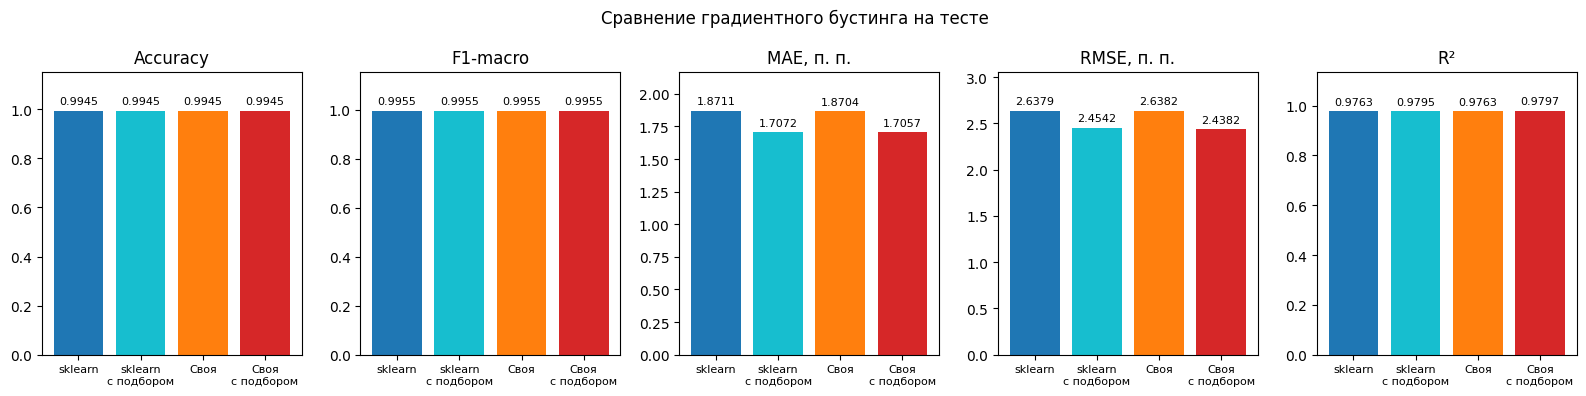

In [16]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
robot_test_summary = classification_summary.xs("Тест", level="Выборка")
cpu_test_summary = regression_summary.xs("Тест", level="Выборка")
test_scores = list(robot_test_summary.items()) + list(cpu_test_summary.items())
labels = ["sklearn", "sklearn\nс подбором", "Своя", "Своя\nс подбором"]
for ax, (metric, scores) in zip(axes, test_scores):
    bars = ax.bar(labels, scores.values, color=["tab:blue", "tab:cyan", "tab:orange", "tab:red"])
    ax.bar_label(bars, fmt="%.4f", padding=3, fontsize=8)
    ax.set_title(metric)
    ax.set_ylim(0, scores.max() * 1.16)
    ax.tick_params(axis="x", labelsize=8)
fig.suptitle("Сравнение градиентного бустинга на тесте")
fig.tight_layout()
plt.show()
plt.close(fig)


### Общий вывод по лабораторной

- **Проверка алгоритмов.** На искусственных данных потери уменьшались с каждым этапом. После 20 этапов MSE составила 0,001447, а кросс-энтропия — 0,003498. Повторное обучение с тем же `random_state` дало те же прогнозы и кривые потерь.
- **Робот.** На кросс-валидации подбор повысил средний F1-macro библиотечной модели с 0,9552 до 0,9574. На отложенном тесте все четыре модели показали Accuracy 0,9945 и F1-macro 0,9955 при округлении до четырёх знаков.
- **CPU.** Параметры, выбранные по кросс-валидации для sklearn, улучшили обе реализации на тесте. MAE снизилась с 1,8711 до 1,7072 п. п. у sklearn и с 1,8704 до 1,7057 п. п. у собственной модели. У улучшенной собственной модели RMSE составила 2,4382 п. п., а R² — 0,9797. У улучшенной sklearn эти метрики составили 2,4542 п. п. и 0,9795.
- **Различия реализаций.** Собственное дерево сравнивает суммы квадратов ошибок через накопленные суммы и использует признаки в `float64`. Бустинг sklearn по умолчанию использует критерий `friedman_mse` и приводит признаки деревьев к `float32`. При близких оценках также может различаться порядок выбора признаков. Из-за другого порога или признака изменяются листья, а затем и остатки на следующих этапах. Для обеих задач качество оказалось близким, а наиболее заметный эффект подбора наблюдался в регрессии.
